In [12]:
from pathlib import Path
import json
import os
import subprocess
import sys

import torch
from IPython.display import display
from PIL import Image

def find_repo_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'scripts' / 'demo_dtd_reference_free_inference.py').is_file():
            return candidate
    raise FileNotFoundError('Could not locate the Research_Paper repository root.')

REPO_ROOT = find_repo_root(Path.cwd())
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

DEVICE = 'cpu'
print('Repository:', REPO_ROOT)
print('Python:', sys.version.split()[0])
print('PyTorch:', torch.__version__)
print('Selected device:', DEVICE)


Repository: D:\Research_Paper
Python: 3.10.11
PyTorch: 2.10.0+cpu
Selected device: cpu


In [13]:
CLASSIFIER_CKPT = REPO_ROOT / (
    'Advanced_Experiments/dtd_position_attack_selected_v1/'
    'dtd_position_attack_selected_v1/suspicious_classifier_best_attack.pt'
)
GENERATOR_CKPT = REPO_ROOT / (
    'Advanced_Experiments/dtd_position_generalizing_generator_v1/'
    'reference_free_generator_best.pt'
)

for label, path in (
    ('Classifier', CLASSIFIER_CKPT),
    ('Generator', GENERATOR_CKPT),
):
    print(f'{label}:', path, 'OK' if path.is_file() else 'MISSING')
    assert path.is_file(), f'Missing {label.lower()} checkpoint: {path}'


Classifier: D:\Research_Paper\Advanced_Experiments\dtd_position_attack_selected_v1\dtd_position_attack_selected_v1\suspicious_classifier_best_attack.pt OK
Generator: D:\Research_Paper\Advanced_Experiments\dtd_position_generalizing_generator_v1\reference_free_generator_best.pt OK


In [14]:
try:
    import ipywidgets as widgets
    uploader = widgets.FileUpload(
        accept='image/png,image/jpeg',
        multiple=False,
        description='Upload image',
    )
    display(uploader)
except ImportError:
    uploader = None
    print('ipywidgets is unavailable. Use the verified fallback or set IMAGE_PATH manually.')


FileUpload(value=(), accept='image/png,image/jpeg', description='Upload image')

Selected image: D:\Research_Paper\demo\uploads\Screenshot 2026-10-08 105938.png


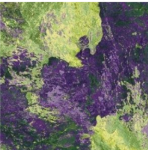

In [15]:
USE_UPLOADED_IMAGE = True  # Change to True after selecting a file above.
VERIFIED_IMAGE = REPO_ROOT / 'Absolute_Dataset/dtd/images/blotchy/blotchy_0025.jpg'
UPLOAD_DIR = REPO_ROOT / 'demo/uploads'

def save_widget_upload(widget, output_dir):
    if widget is None or not widget.value:
        raise RuntimeError('Select an image with the upload widget first.')
    output_dir.mkdir(parents=True, exist_ok=True)
    value = widget.value
    if isinstance(value, dict):
        name, item = next(iter(value.items()))
        content = item['content']
    else:
        item = value[0]
        name = item['name']
        content = item['content']
    path = output_dir / Path(name).name
    path.write_bytes(bytes(content))
    return path

if USE_UPLOADED_IMAGE:
    IMAGE_PATH = save_widget_upload(uploader, UPLOAD_DIR)
else:
    IMAGE_PATH = VERIFIED_IMAGE

assert IMAGE_PATH.is_file(), f'Missing input image: {IMAGE_PATH}'
print('Selected image:', IMAGE_PATH)
display(Image.open(IMAGE_PATH).convert('RGB'))



Stage 1: Original image and normal prediction


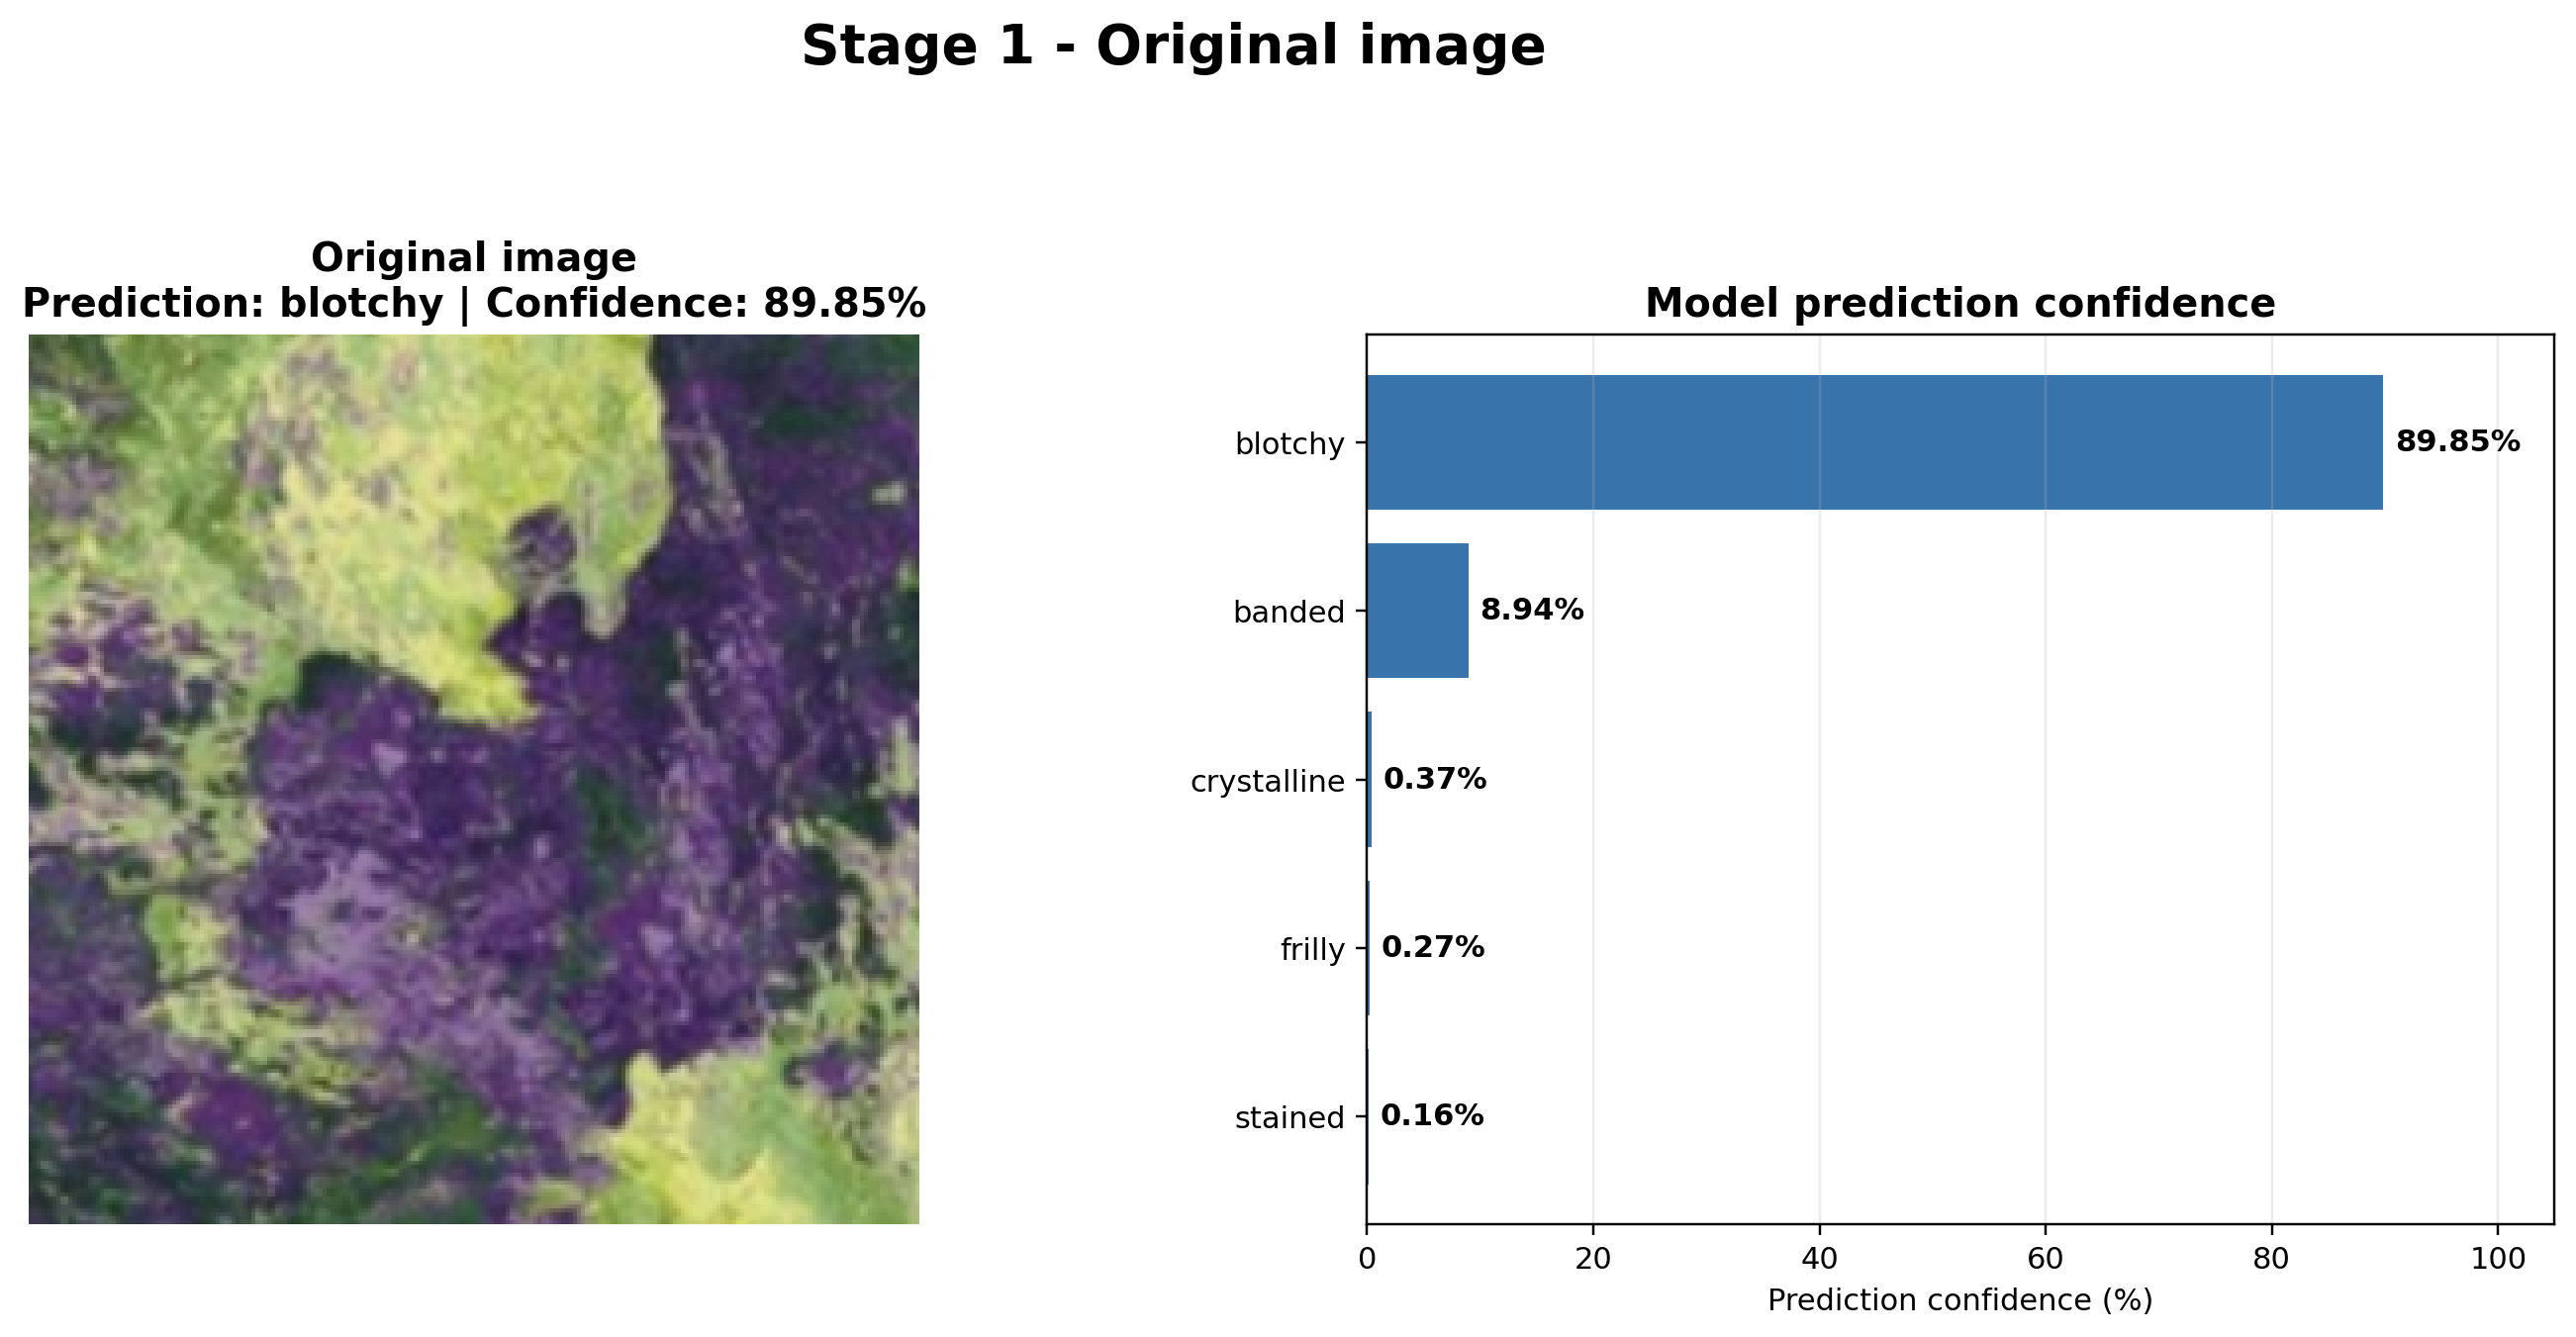


Stage 2: Trigger added to the image


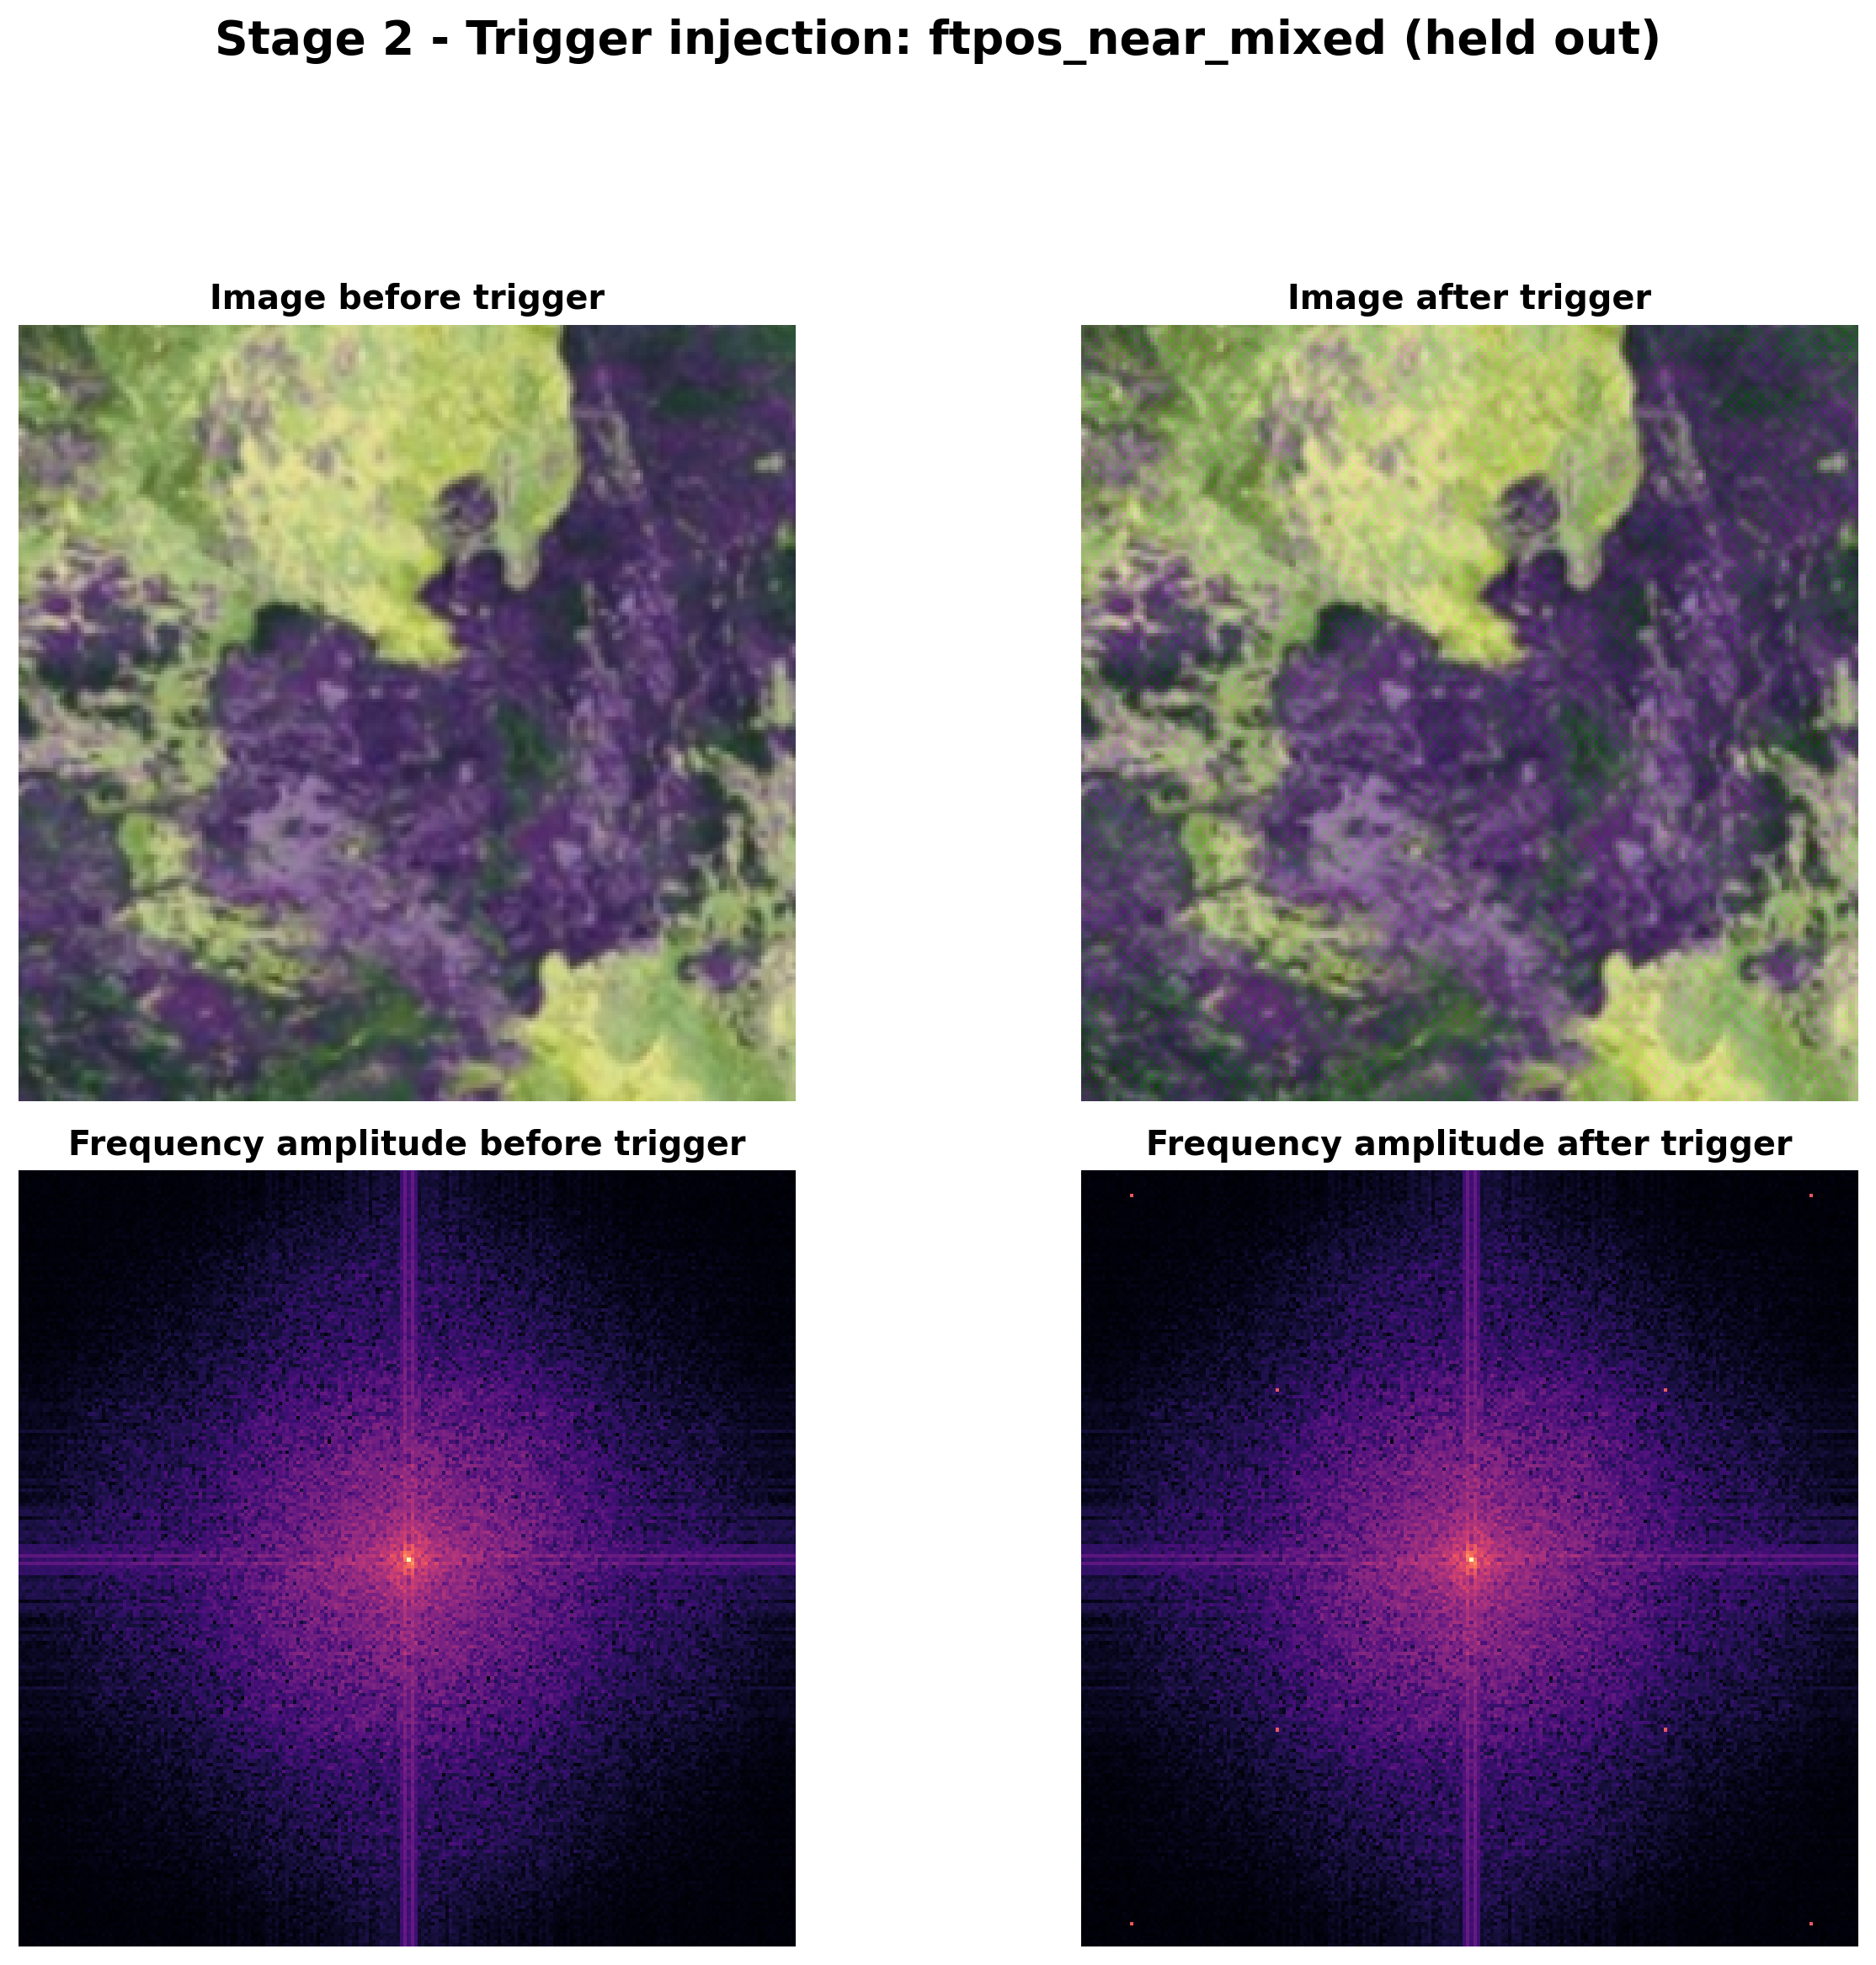


Stage 3: Poisoned model result without generator


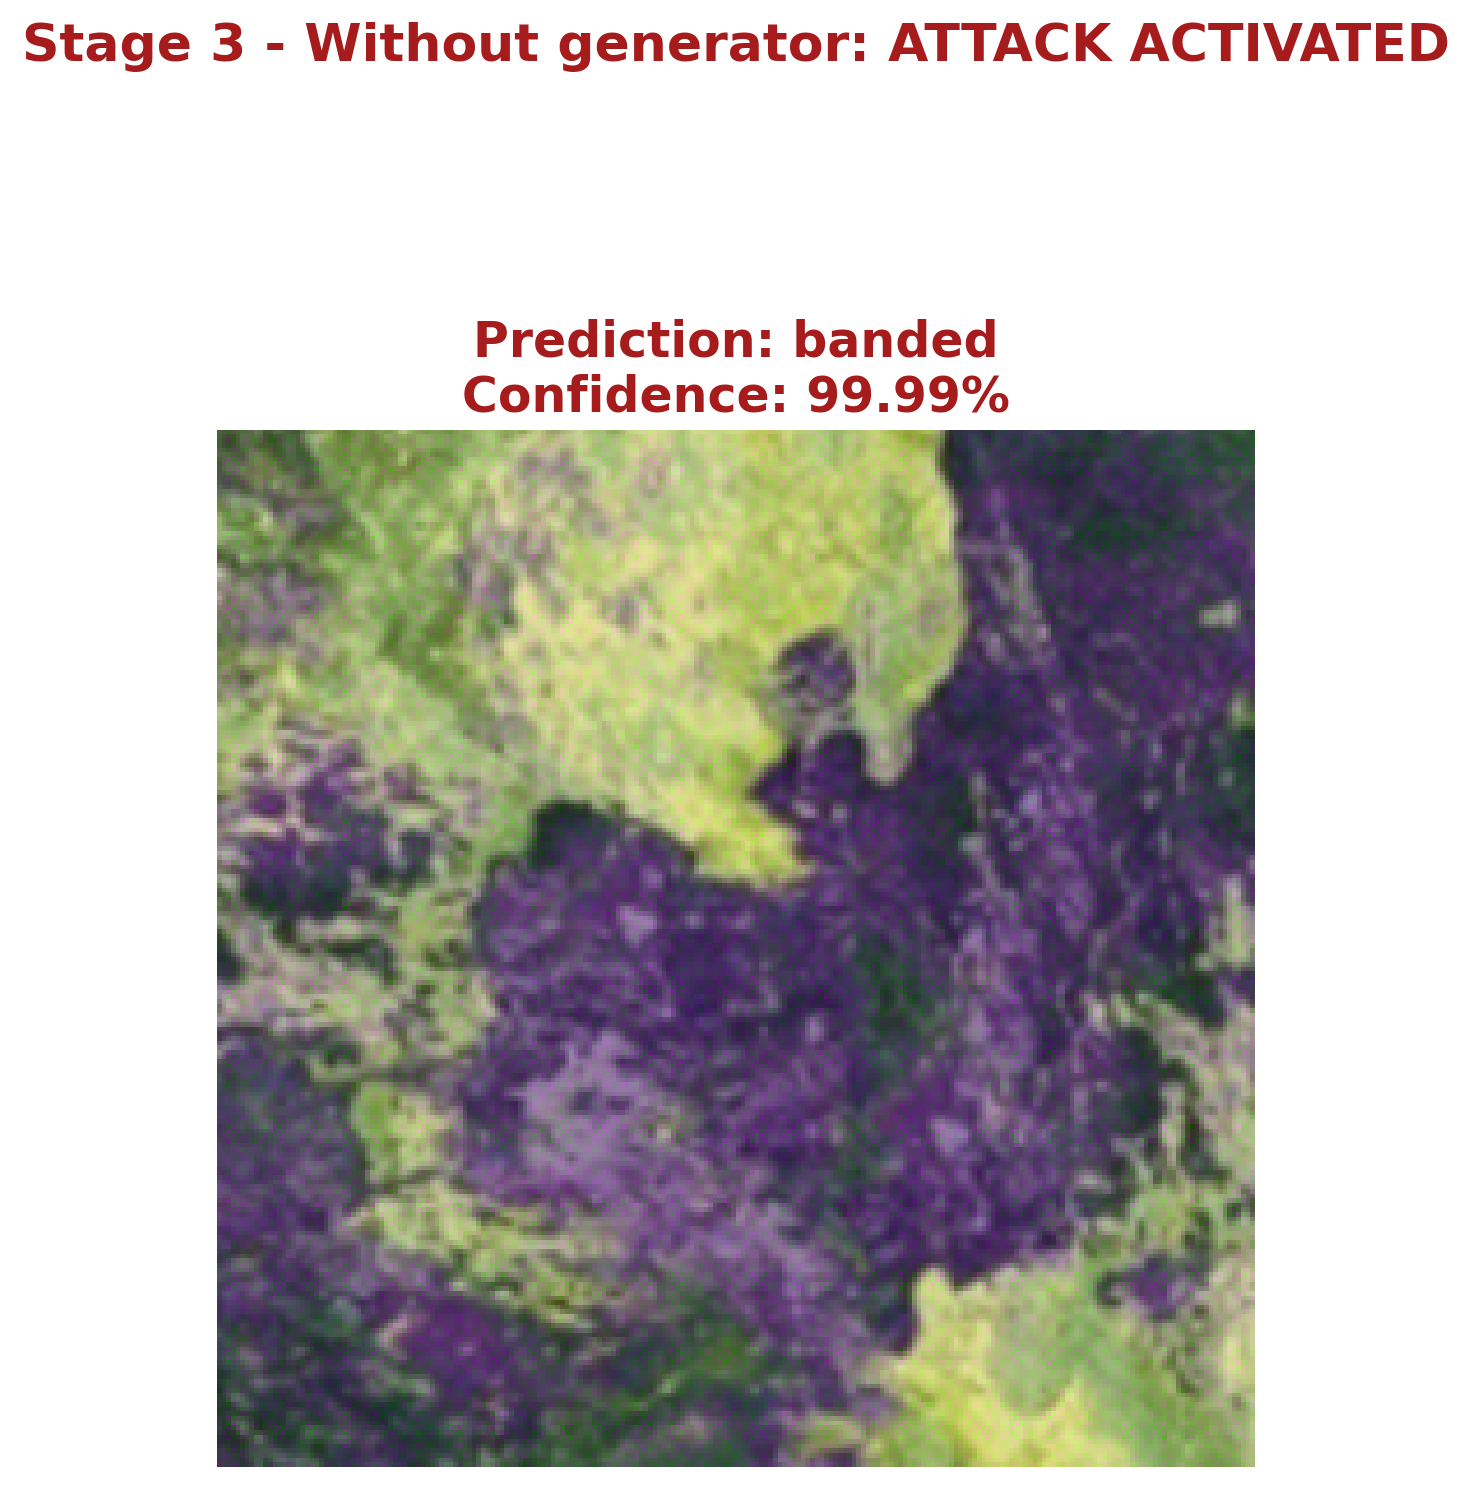


Stage 4: Triggered image processed by the generator


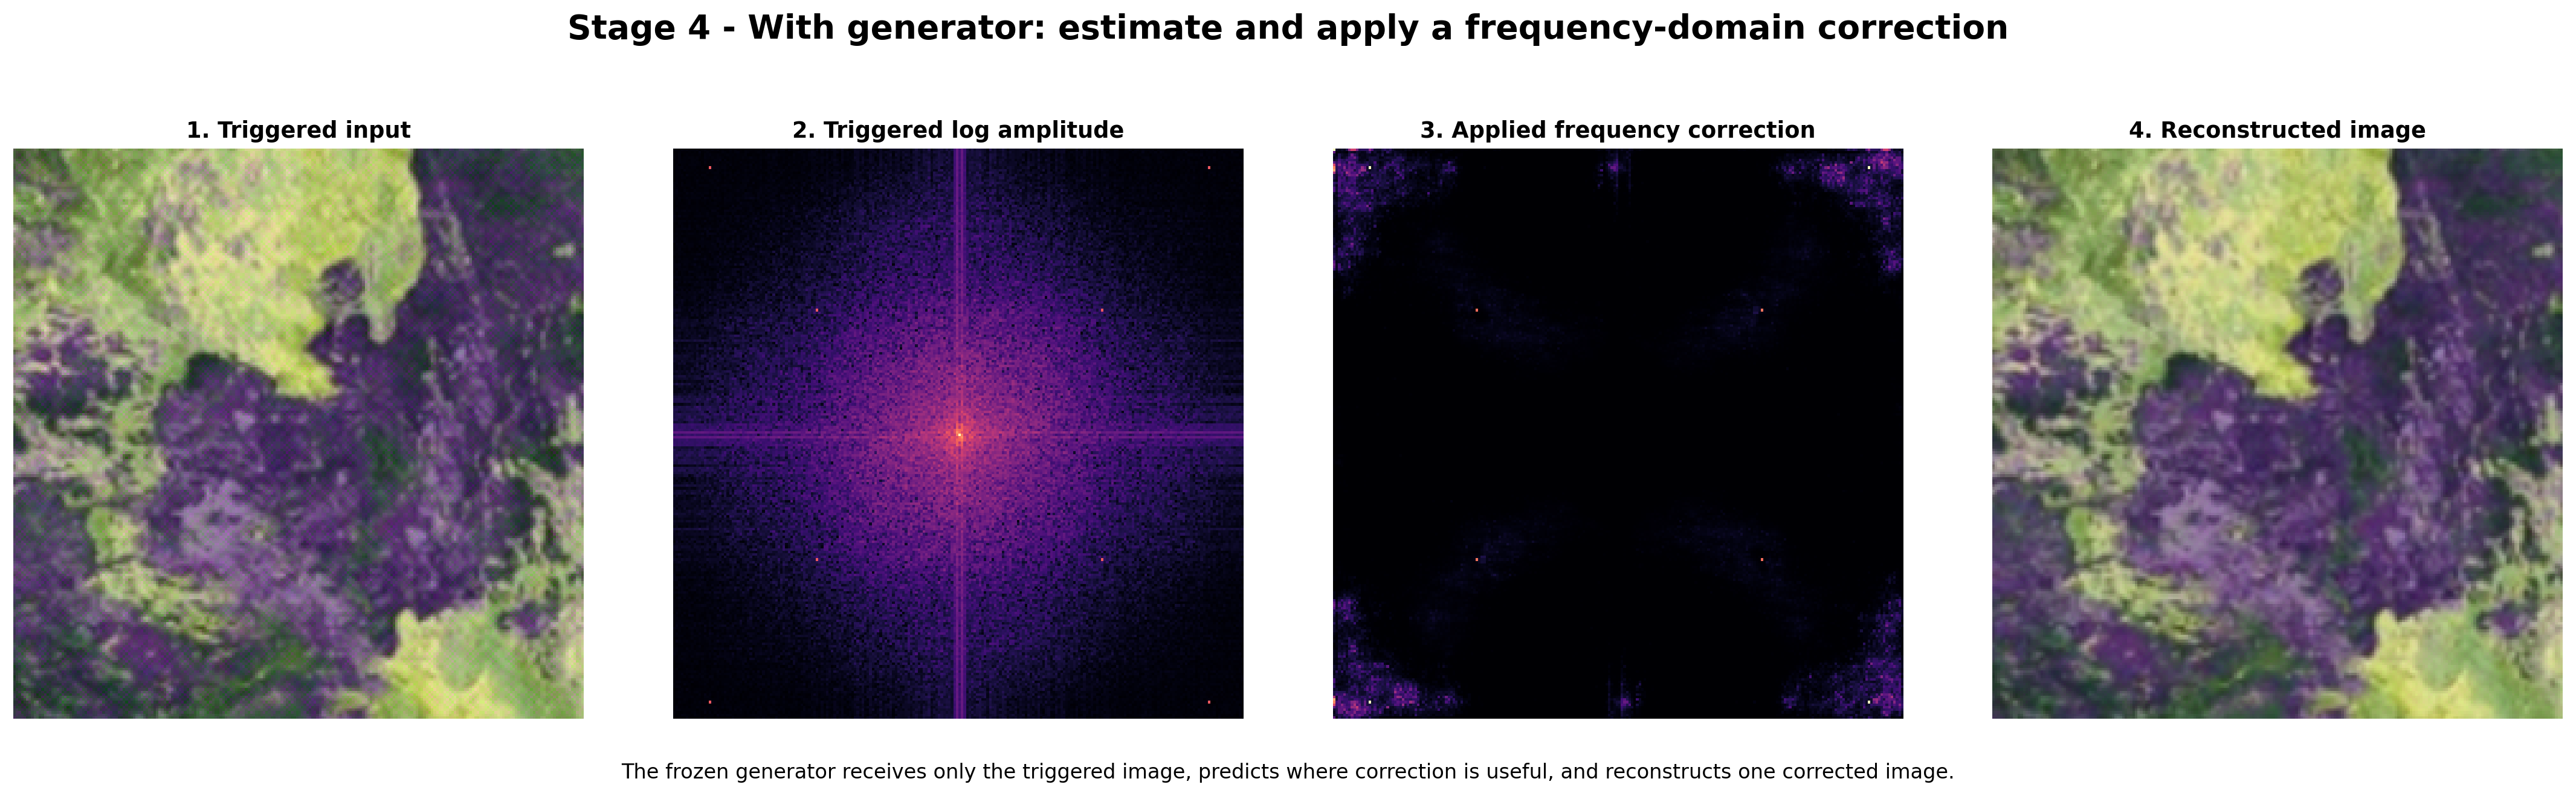


Stage 5: Final comparison and defended result


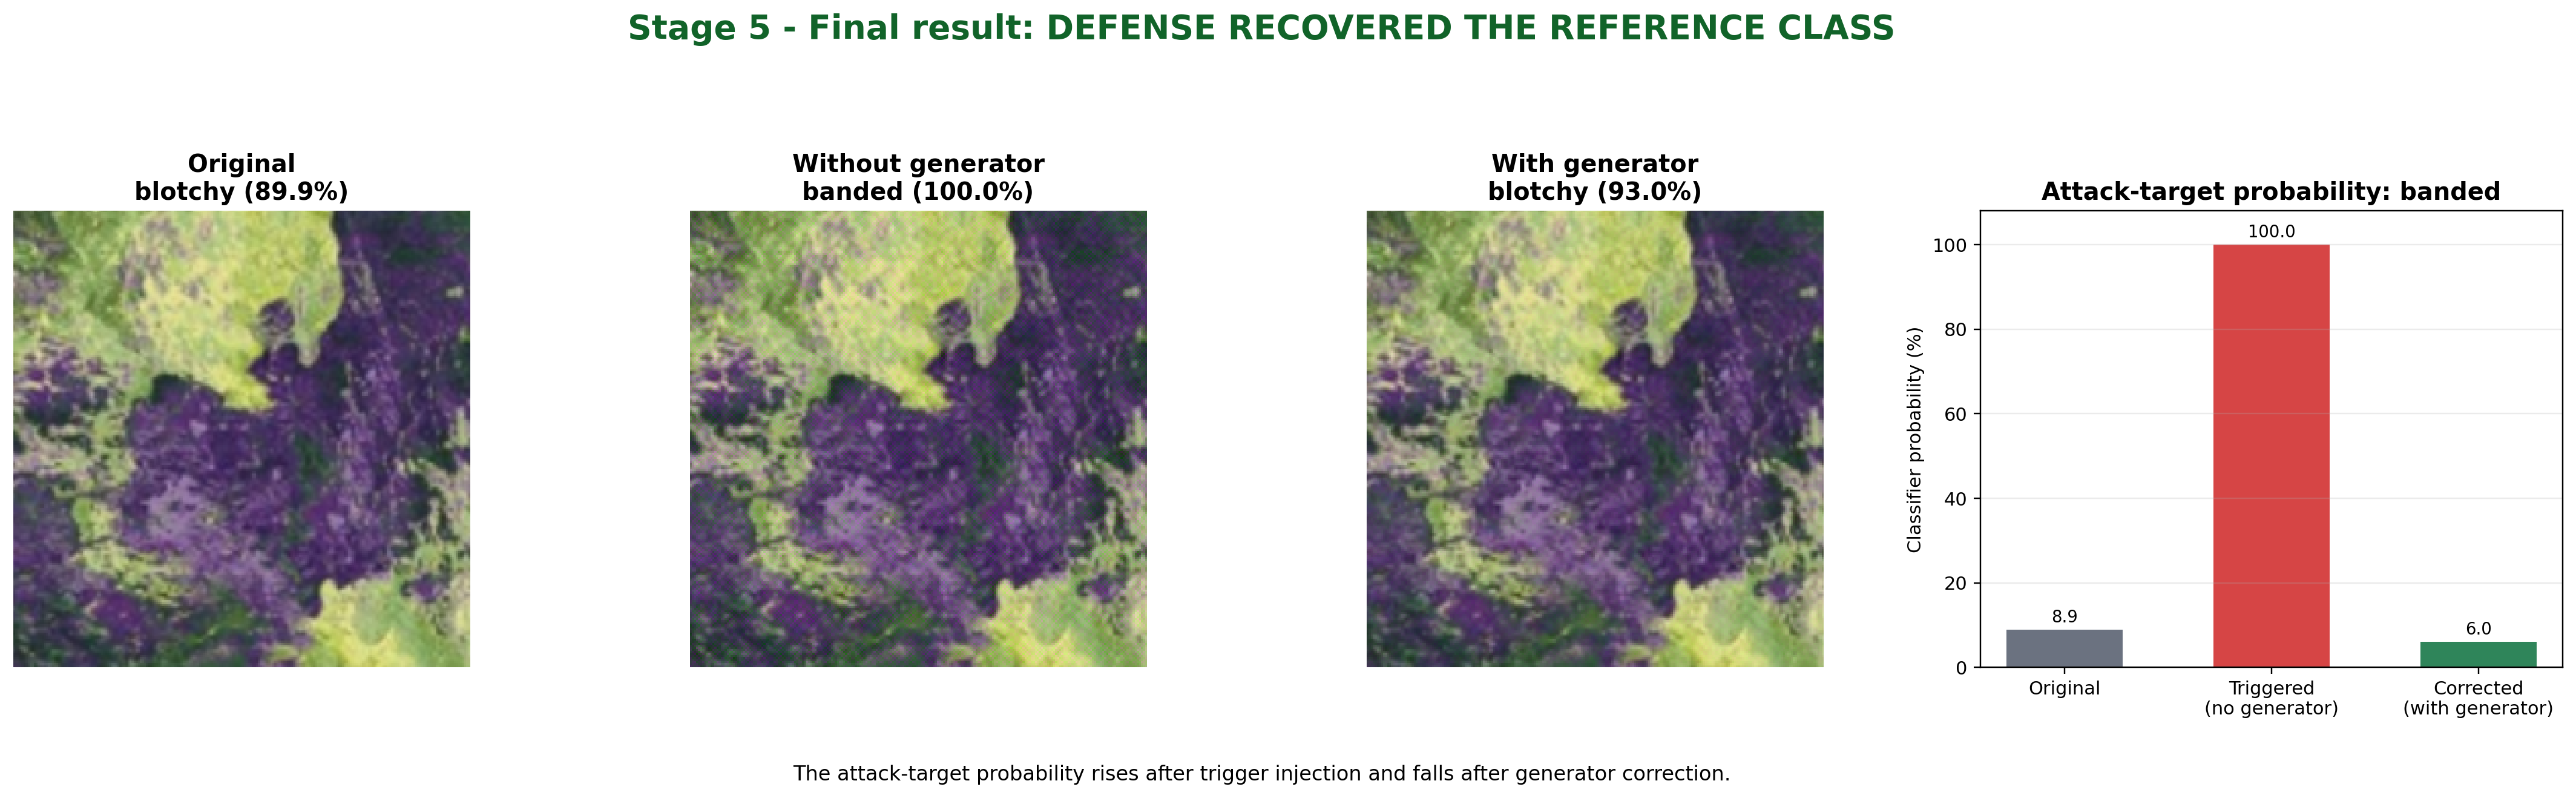

In [16]:
CONTROLLED_OUTPUT = REPO_ROOT / 'Advanced_Outputs/dtd_cpu_demo/controlled'

controlled_command = [
    sys.executable,
    '-m', 'scripts.demo_dtd_reference_free_inference',
    '--image', str(IMAGE_PATH),
    '--mode', 'controlled',
    '--trigger-name', 'ftpos_near_mixed',
    '--classifier-checkpoint', str(CLASSIFIER_CKPT),
    '--generator-checkpoint', str(GENERATOR_CKPT),
    '--output-dir', str(CONTROLLED_OUTPUT),
    '--device', DEVICE,
]

subprocess.run(controlled_command, check=True)

stage_sequence = [
    ('Stage 1: Original image and normal prediction', '01_original_image.png'),
    ('Stage 2: Trigger added to the image', '02_trigger_injection.png'),
    ('Stage 3: Poisoned model result without generator', '03_without_generator.png'),
    ('Stage 4: Triggered image processed by the generator', '04_with_generator.png'),
    ('Stage 5: Final comparison and defended result', '05_final_result.png'),
]

for heading, filename in stage_sequence:
    print('\n' + '=' * 90)
    print(heading)
    print('=' * 90)
    display(Image.open(CONTROLLED_OUTPUT / filename))


In [17]:
controlled_report = json.loads(
    (CONTROLLED_OUTPUT / 'demo_report.json').read_text(encoding='utf-8')
)
print('Attack activated:', controlled_report['attack_activated'])
print('Recovered to reference class:', controlled_report['recovered_to_reference_class'])
print(json.dumps(controlled_report['predictions'], indent=2))


Attack activated: True
Recovered to reference class: True
{
  "input": {
    "class": "banded",
    "confidence": 0.9999350309371948,
    "top_k": [
      {
        "class": "banded",
        "probability": 0.9999350309371948
      },
      {
        "class": "blotchy",
        "probability": 1.522847651358461e-05
      },
      {
        "class": "matted",
        "probability": 4.6806931095488835e-06
      },
      {
        "class": "chequered",
        "probability": 3.579787744456553e-06
      },
      {
        "class": "zigzagged",
        "probability": 3.0487319691019366e-06
      }
    ],
    "tracked_probabilities": {
      "banded": 0.9999350309371948
    }
  },
  "corrected": {
    "class": "blotchy",
    "confidence": 0.9304154515266418,
    "top_k": [
      {
        "class": "blotchy",
        "probability": 0.9304154515266418
      },
      {
        "class": "banded",
        "probability": 0.05981580168008804
      },
      {
        "class": "crystalline",
        "

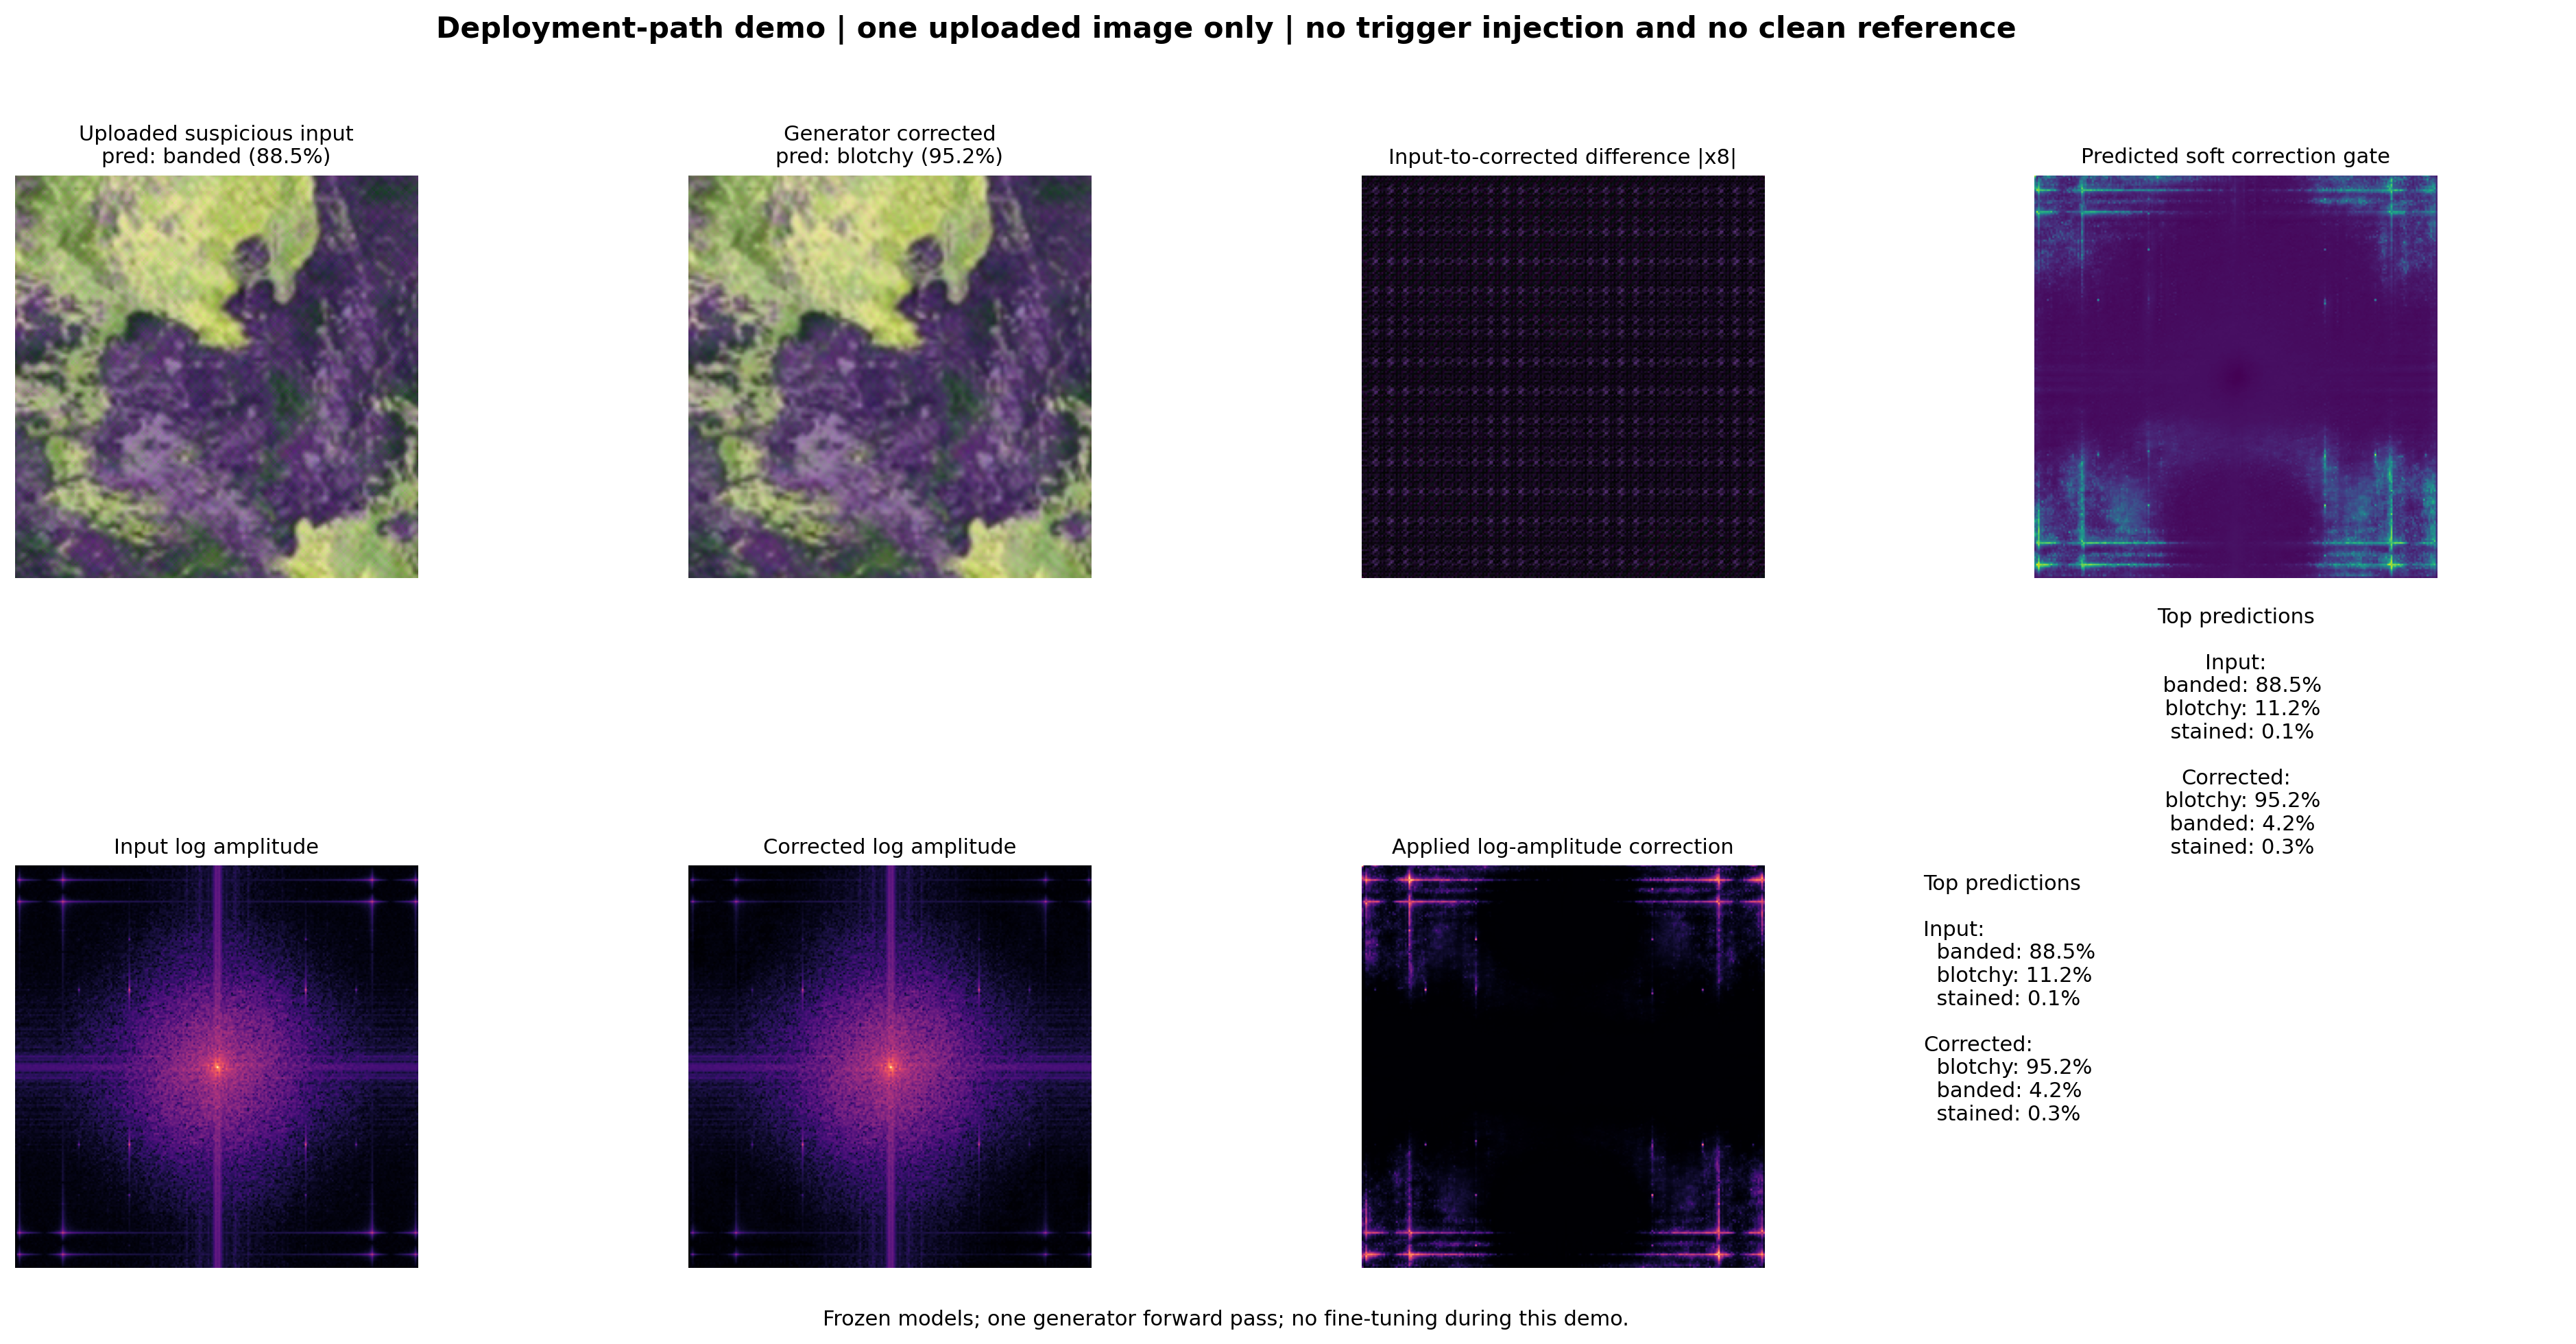

In [18]:
SUSPICIOUS_IMAGE = CONTROLLED_OUTPUT / 'triggered_image.png'
SUSPICIOUS_OUTPUT = REPO_ROOT / 'Advanced_Outputs/dtd_cpu_demo/suspicious'

suspicious_command = [
    sys.executable,
    '-m', 'scripts.demo_dtd_reference_free_inference',
    '--image', str(SUSPICIOUS_IMAGE),
    '--mode', 'suspicious',
    '--classifier-checkpoint', str(CLASSIFIER_CKPT),
    '--generator-checkpoint', str(GENERATOR_CKPT),
    '--output-dir', str(SUSPICIOUS_OUTPUT),
    '--device', DEVICE,
]

subprocess.run(suspicious_command, check=True)
display(Image.open(SUSPICIOUS_OUTPUT / 'demo_panel.png'))


In [19]:
suspicious_report = json.loads(
    (SUSPICIOUS_OUTPUT / 'demo_report.json').read_text(encoding='utf-8')
)
print('Generator received clean counterpart:', suspicious_report['generator_received_clean_counterpart'])
print('Prediction changed:', suspicious_report['prediction_changed'])
print(json.dumps(suspicious_report['predictions'], indent=2))


Generator received clean counterpart: False
Prediction changed: True
{
  "input": {
    "class": "banded",
    "confidence": 0.8848759531974792,
    "top_k": [
      {
        "class": "banded",
        "probability": 0.8848759531974792
      },
      {
        "class": "blotchy",
        "probability": 0.11240935325622559
      },
      {
        "class": "stained",
        "probability": 0.0006472195964306593
      },
      {
        "class": "matted",
        "probability": 0.00022546759282704443
      },
      {
        "class": "frilly",
        "probability": 0.00019989805878140032
      }
    ],
    "tracked_probabilities": {
      "banded": 0.8848759531974792
    }
  },
  "corrected": {
    "class": "blotchy",
    "confidence": 0.9522044658660889,
    "top_k": [
      {
        "class": "blotchy",
        "probability": 0.9522044658660889
      },
      {
        "class": "banded",
        "probability": 0.04176706075668335
      },
      {
        "class": "stained",
        "